# Assignment 06 - Notebook 02: Khám Phá Dữ Liệu Chuyên Sâu (Deep EDA) & Tiền Xử Lý Chuỗi Đa Miền

**Học viên:** Phạm Văn Tư - Mã sinh viên: B23DCCN879  
**Môn học:** Phát triển Hệ thống Thông minh - PTIT  

Notebook này thực hiện quy trình kiểm toán, phân tích khám phá (EDA) và đóng gói tiền xử lý cho 2 bộ dữ liệu lớn:
1. **Dữ liệu Chuỗi Thời Gian Chứng Khoán:** Cổ phiếu Amazon (AMZN) với 6,903 phiên giao dịch liên tục từ 1997 đến 2024 (27 năm).
2. **Dữ liệu Chuỗi Hành Vi Khách Hàng:** 60,000 bản ghi theo dõi 5,000 khách hàng qua 12 tháng liên tục để dự đoán rủi ro rời bỏ dịch vụ (Customer Churn).
3. **Kỹ thuật Cửa Sổ Trượt (Sliding Window):** Cấu trúc hóa chuỗi thành Tensor 3D chuẩn học sâu `(N, T, D)` phục vụ các mô hình RNN, LSTM, GRU, BiLSTM.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Cấu hình đồ họa chuẩn mực học thuật
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['axes.unicode_minus'] = False

BASE_DIR = os.path.dirname(os.path.abspath(''))
STOCK_CSV = os.path.join(BASE_DIR, 'data', 'stock_market', 'amazon_stock_price.csv')
CUST_CSV = os.path.join(BASE_DIR, 'data', 'customer_behavior', 'customer_sequential_behavior.csv')
PROCESSED_DIR = os.path.join(BASE_DIR, 'data', 'processed')
os.makedirs(PROCESSED_DIR, exist_ok=True)

print("Đường dẫn file dữ liệu:")
print(f"  - Cổ phiếu Amazon: {STOCK_CSV}")
print(f"  - Hành vi khách hàng: {CUST_CSV}")


Đường dẫn file dữ liệu:
  - Cổ phiếu Amazon: /Users/phamvantu/Desktop/INTEL_SYS/src/Assigment 06/data/stock_market/amazon_stock_price.csv
  - Hành vi khách hàng: /Users/phamvantu/Desktop/INTEL_SYS/src/Assigment 06/data/customer_behavior/customer_sequential_behavior.csv


## 1. Khám Phá Cấu Trúc Chuỗi Thời Gian Cổ Phiếu Amazon (AMZN)
Kiểm tra cấu trúc dữ liệu, các trường thông tin OHLCV, chỉ báo kỹ thuật MA-20, MA-50, RSI-14, độ biến động lịch sử 20 ngày và tỷ suất sinh lời logarit.


In [2]:
df_stock = pd.read_csv(STOCK_CSV)
df_stock['Date'] = pd.to_datetime(df_stock['Date'])
print(f"Tổng số phiên giao dịch: {len(df_stock):,}")
print(f"Khoảng thời gian: Từ {df_stock['Date'].min().strftime('%d/%m/%Y')} đến {df_stock['Date'].max().strftime('%d/%m/%Y')} (27 năm)")
print(f"Số lượng giá trị khuyết thiếu (Missing values): {df_stock.isnull().sum().sum()}")
display(df_stock.info())
display(df_stock.describe().round(4))


Tổng số phiên giao dịch: 6,903
Khoảng thời gian: Từ 25/07/1997 đến 30/12/2024 (27 năm)
Số lượng giá trị khuyết thiếu (Missing values): 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6903 entries, 0 to 6902
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           6903 non-null   datetime64[ns]
 1   Close          6903 non-null   float64       
 2   High           6903 non-null   float64       
 3   Low            6903 non-null   float64       
 4   Open           6903 non-null   float64       
 5   Volume         6903 non-null   int64         
 6   Return         6903 non-null   float64       
 7   MA20           6903 non-null   float64       
 8   MA50           6903 non-null   float64       
 9   Volatility_20  6903 non-null   float64       
 10  RSI_14         6903 non-null   float64       
dtypes: datetime64[ns](1), float64(9), int64(1)
memory usage: 593.4 KB


None

,Date,Close,High,Low,Open,Volume,Return,MA20,MA50,Volatility_20,RSI_14
count,6903,6903.0000,6903.0000,6903.0000,6903.0000,6.903000e+03,6903.0000,6903.0000,6903.0000,6903.0000,6903.0000
mean,2011-04-12 21:03:56.245110784,40.0192,40.4946,39.5190,40.0261,1.366227e+08,0.0017,39.7086,39.2494,0.0292,53.8080
min,1997-07-25 00:00:00,0.1021,0.1026,0.0969,0.1026,9.744000e+06,-0.2477,0.1048,0.0886,0.0049,7.3833
25%,2004-06-05 12:00:00,2.1305,2.1652,2.0932,2.1243,6.371300e+07,-0.0129,2.1326,2.1512,0.0154,41.3276
50%,2011-04-12 00:00:00,9.0630,9.1805,8.9505,9.0810,1.010440e+08,0.0005,9.0384,8.9970,0.0233,53.9684
75%,2018-02-20 12:00:00,71.4250,72.6045,69.5578,71.4912,1.556960e+08,0.0146,70.6422,64.8277,0.0358,65.9398
max,2024-12-30 00:00:00,232.9300,233.0000,228.0100,232.3900,2.086584e+09,0.3447,224.3365,209.2372,0.1118,97.3656
std,NaN,56.8128,57.4686,56.1350,56.8309,1.370723e+08,0.0350,56.3567,55.7406,0.0195,16.8293


### 1.1. Diễn Biến Giá Đóng Cửa, Đường Trung Bình Động & Thanh Khoản Volume

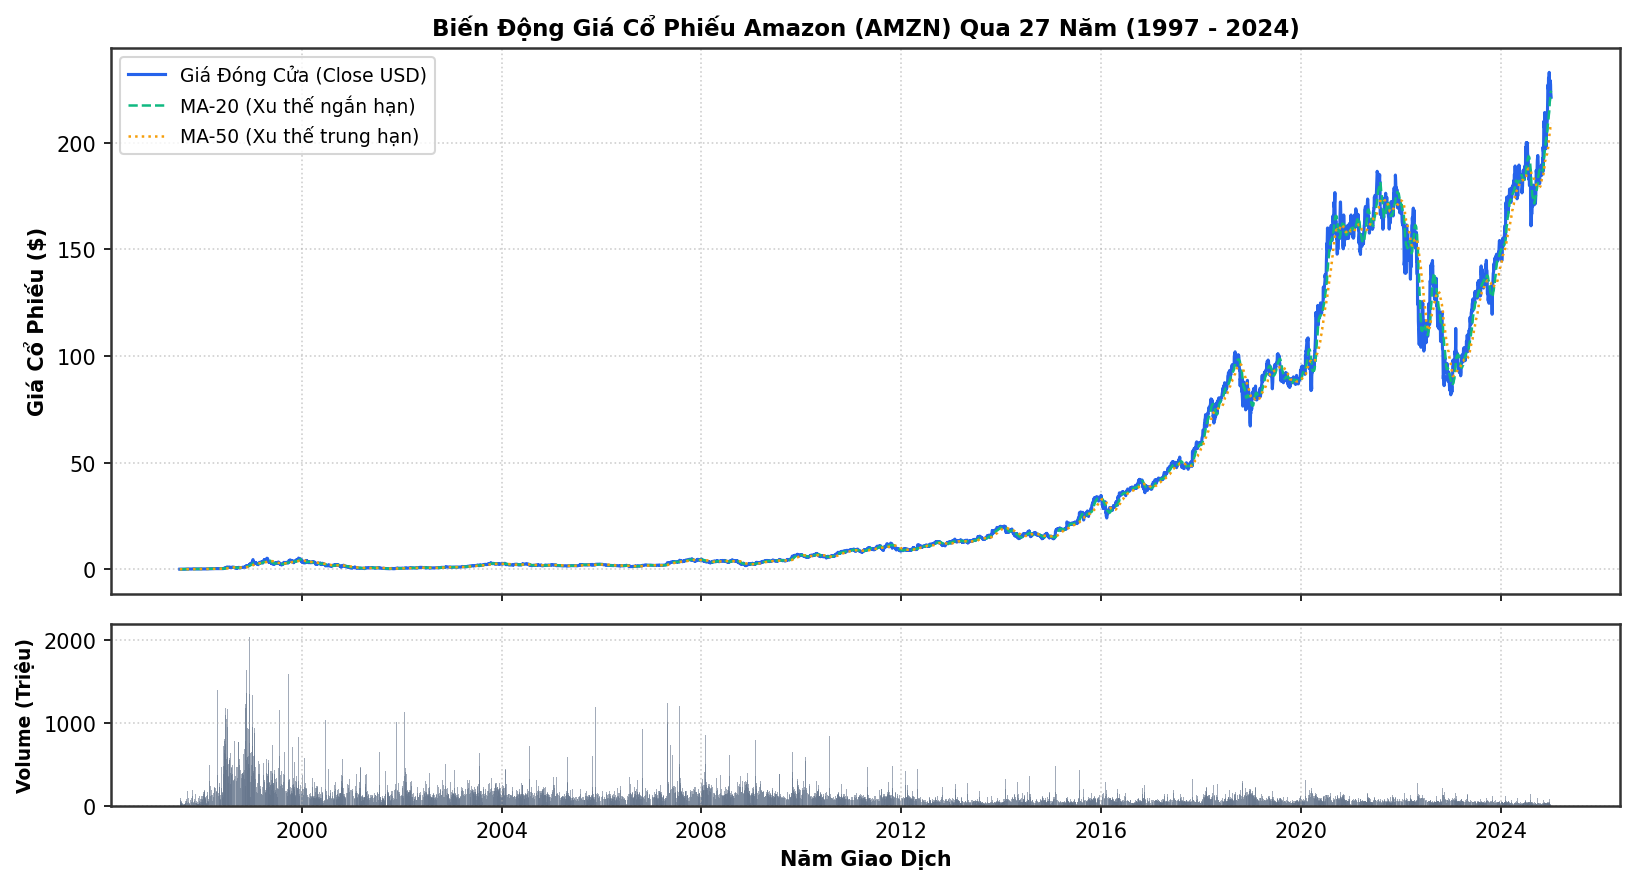

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]}, dpi=150)

ax1.plot(df_stock['Date'], df_stock['Close'], color='#2563eb', lw=1.5, label="Giá Đóng Cửa (Close USD)")
ax1.plot(df_stock['Date'], df_stock['MA20'], color='#10b981', lw=1.2, linestyle='--', label="MA-20 (Xu thế ngắn hạn)")
ax1.plot(df_stock['Date'], df_stock['MA50'], color='#f59e0b', lw=1.2, linestyle=':', label="MA-50 (Xu thế trung hạn)")
ax1.set_ylabel("Giá Cổ Phiếu ($)", fontsize=10, fontweight='bold')
ax1.set_title("Biến Động Giá Cổ Phiếu Amazon (AMZN) Qua 27 Năm (1997 - 2024)", fontsize=11, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper left', fontsize=9)

ax2.bar(df_stock['Date'], df_stock['Volume'] / 1e6, color='#64748b', alpha=0.6, width=4)
ax2.set_ylabel("Volume (Triệu)", fontsize=9, fontweight='bold')
ax2.set_xlabel("Năm Giao Dịch", fontsize=10, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


### 1.2. Phân Tích Lợi Nhuận, Tụ Cụm Biến Động (ARCH Effect), Đuôi Béo & Tương Quan Đa Chiều

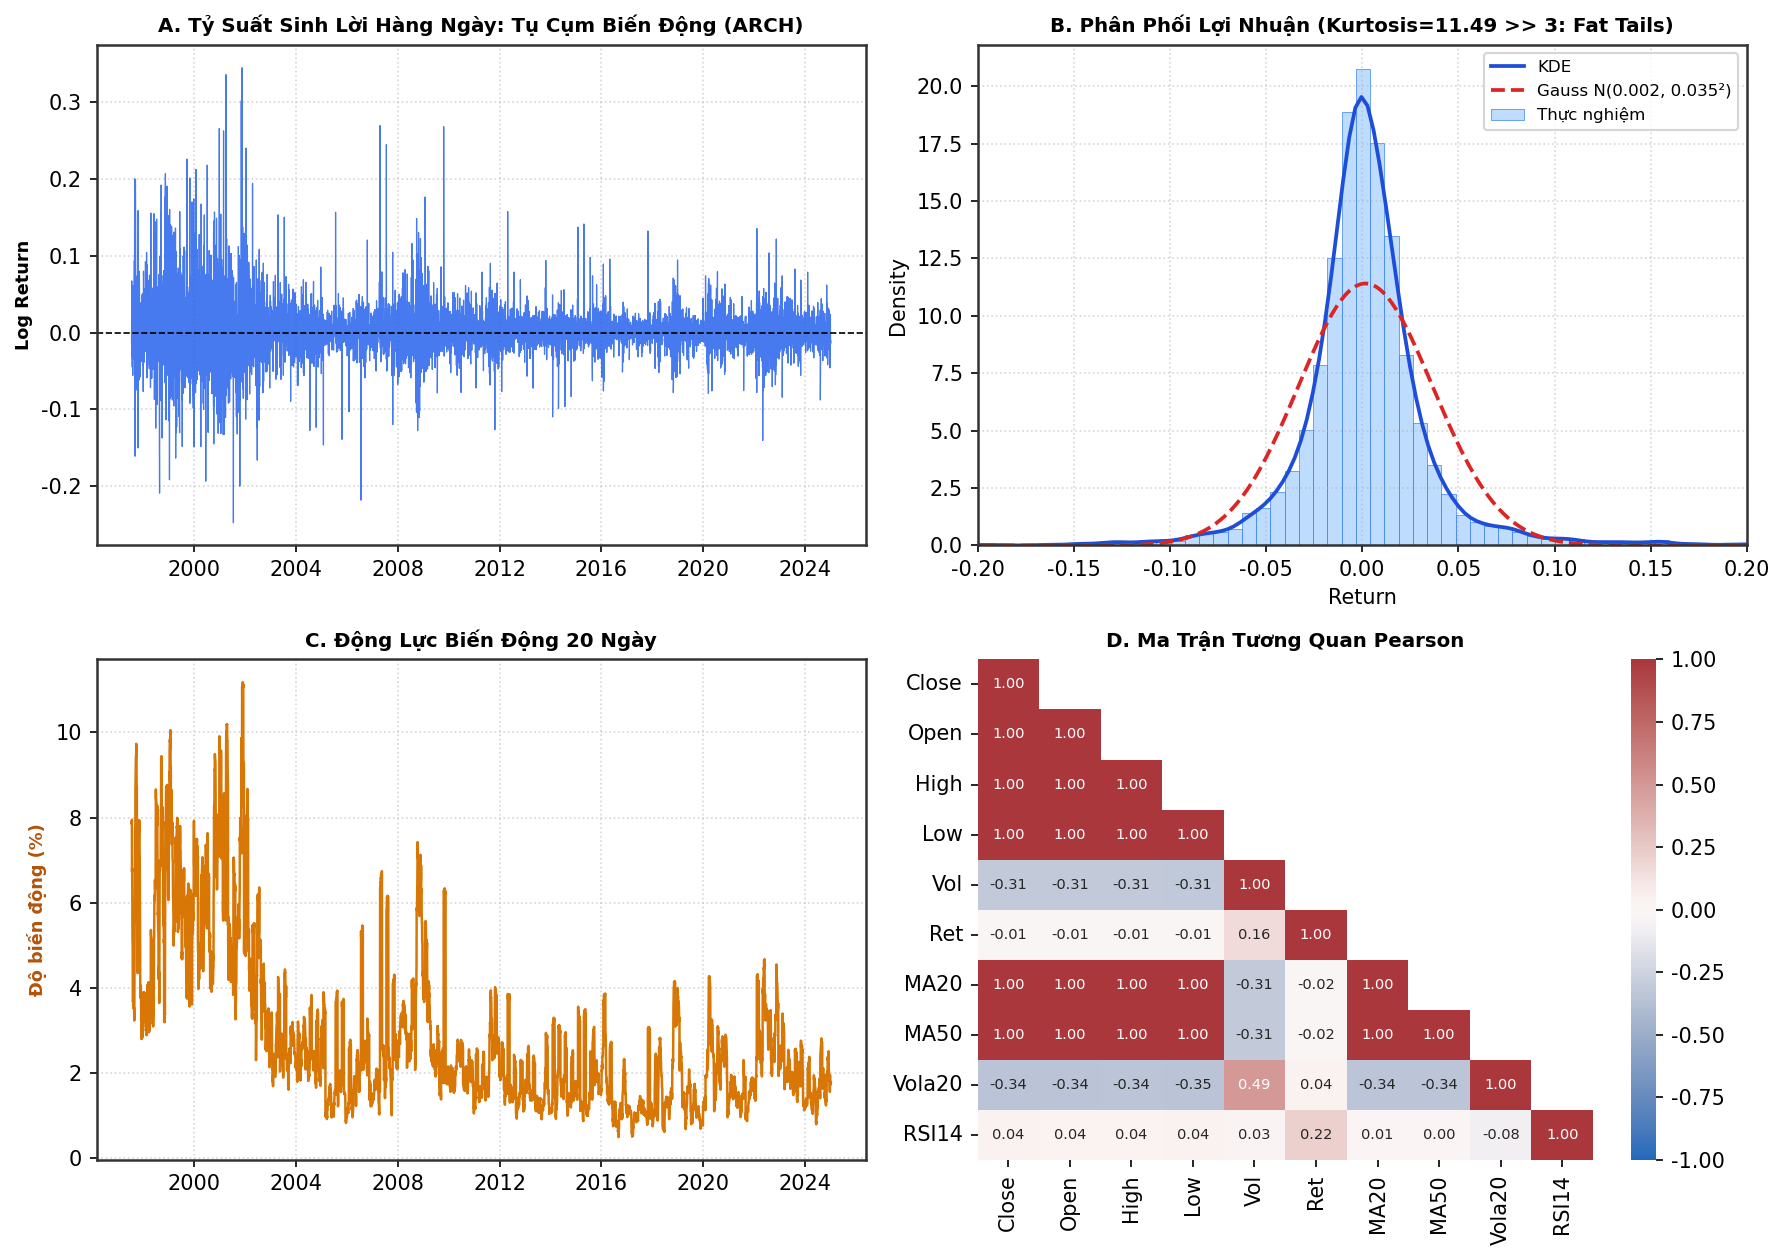

Thống kê Lợi nhuận: Trung bình = 0.001699, Độ lệch chuẩn = 0.034968
Độ lệch (Skewness) = 1.0507 (lệch phải dương do các phiên bùng nổ)
Độ nhọn (Kurtosis) = 11.4858 (>> 3, khẳng định hiện tượng Đuôi Béo Leptokurtic)


In [4]:
returns = df_stock['Return'].dropna()
mu, sigma = returns.mean(), returns.std()
skew_val = stats.skew(returns)
kurt_val = stats.kurtosis(returns)

fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), dpi=150)
plt.subplots_adjust(wspace=0.25, hspace=0.30)

# A. Log Returns & Volatility Clustering
axes[0, 0].plot(df_stock['Date'], df_stock['Return'], color='#2563eb', lw=0.6, alpha=0.85)
axes[0, 0].axhline(0, color='black', lw=0.8, linestyle='--')
axes[0, 0].set_title("A. Tỷ Suất Sinh Lời Hàng Ngày: Tụ Cụm Biến Động (ARCH)", fontsize=9.5, fontweight='bold')
axes[0, 0].set_ylabel("Log Return", fontsize=8.5, fontweight='bold')
axes[0, 0].grid(True, linestyle=':', alpha=0.5)

# B. Empirical Distribution vs Gaussian Normal
x_grid = np.linspace(-0.25, 0.25, 500)
pdf_norm = stats.norm.pdf(x_grid, mu, sigma)
sns.histplot(returns, bins=80, stat='density', ax=axes[0, 1], color='#93c5fd', edgecolor='#3b82f6', alpha=0.6, label='Thực nghiệm')
sns.kdeplot(returns, ax=axes[0, 1], color='#1d4ed8', lw=1.8, label='KDE')
axes[0, 1].plot(x_grid, pdf_norm, color='#dc2626', lw=1.8, linestyle='--', label=f'Gauss N({mu:.3f}, {sigma:.3f}²)')
axes[0, 1].set_title(f"B. Phân Phối Lợi Nhuận (Kurtosis={kurt_val:.2f} >> 3: Fat Tails)", fontsize=9.5, fontweight='bold')
axes[0, 1].set_xlim(-0.2, 0.2)
axes[0, 1].legend(fontsize=8)
axes[0, 1].grid(True, linestyle=':', alpha=0.5)

# C. Volatility & Volume
axes[1, 0].plot(df_stock['Date'], df_stock['Volatility_20'] * 100, color='#d97706', lw=1.2, label='Độ biến động 20 ngày (%)')
axes[1, 0].set_ylabel("Độ biến động (%)", fontsize=8.5, fontweight='bold', color='#b45309')
axes[1, 0].set_title("C. Động Lực Biến Động 20 Ngày", fontsize=9.5, fontweight='bold')
axes[1, 0].grid(True, linestyle=':', alpha=0.5)

# D. Correlation Heatmap
features = ['Close', 'Open', 'High', 'Low', 'Volume', 'Return', 'MA20', 'MA50', 'Volatility_20', 'RSI_14']
short_lbl = ['Close', 'Open', 'High', 'Low', 'Vol', 'Ret', 'MA20', 'MA50', 'Vola20', 'RSI14']
corr_m = df_stock[features].corr()
mask = np.triu(np.ones_like(corr_m, dtype=bool), k=1)
sns.heatmap(corr_m, mask=mask, cmap='vlag', vmin=-1, vmax=1, annot=True, fmt='.2f',
            ax=axes[1, 1], xticklabels=short_lbl, yticklabels=short_lbl, annot_kws={'size': 7})
axes[1, 1].set_title("D. Ma Trận Tương Quan Pearson", fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Thống kê Lợi nhuận: Trung bình = {mu:.6f}, Độ lệch chuẩn = {sigma:.6f}")
print(f"Độ lệch (Skewness) = {skew_val:.4f} (lệch phải dương do các phiên bùng nổ)")
print(f"Độ nhọn (Kurtosis) = {kurt_val:.4f} (>> 3, khẳng định hiện tượng Đuôi Béo Leptokurtic)")


## 2. Phân Tích Tính Dừng & Hàm Tự Tương Quan (ACF/PACF)
Giá gốc thể hiện tính xu hướng mạnh (Non-stationary), trong khi chuỗi tỷ suất sinh lời (Returns) là chuỗi dừng (Stationary).


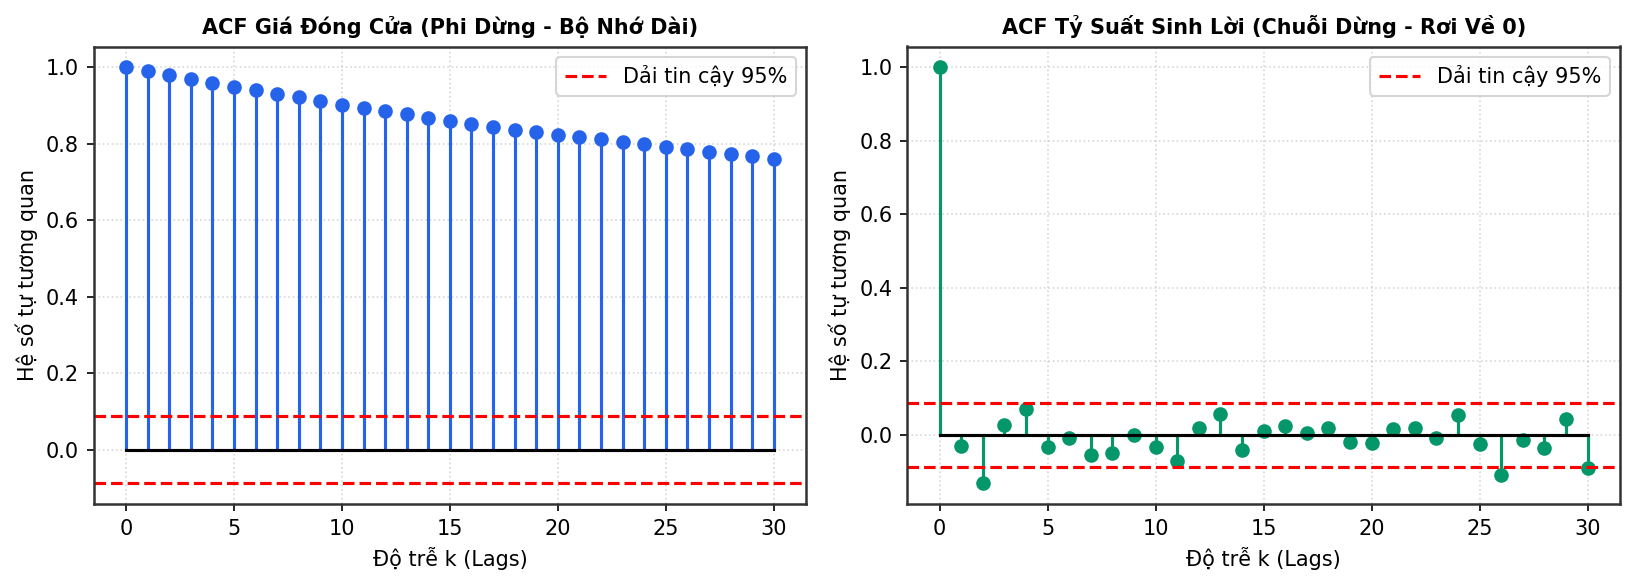

In [5]:
def calc_acf(series, lags=30):
    n = len(series)
    mean = np.mean(series)
    c0 = np.sum((series - mean)**2) / n
    return [np.sum((series[:n-l] - mean) * (series[l:] - mean)) / (n * c0) for l in range(lags + 1)]

recent_close = df_stock['Close'].values[-500:]
recent_ret = df_stock['Return'].values[-500:]

acf_close = calc_acf(recent_close, 30)
acf_ret = calc_acf(recent_ret, 30)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.0), dpi=150)
lags = range(31)

ax1.stem(lags, acf_close, linefmt='#2563eb', markerfmt='o', basefmt='k-')
ax1.axhline(1.96 / np.sqrt(500), color='r', linestyle='--', label='Dải tin cậy 95%')
ax1.axhline(-1.96 / np.sqrt(500), color='r', linestyle='--')
ax1.set_title("ACF Giá Đóng Cửa (Phi Dừng - Bộ Nhớ Dài)", fontsize=10, fontweight='bold')
ax1.set_xlabel("Độ trễ k (Lags)")
ax1.set_ylabel("Hệ số tự tương quan")
ax1.grid(True, linestyle=':', alpha=0.5)
ax1.legend()

ax2.stem(lags, acf_ret, linefmt='#059669', markerfmt='o', basefmt='k-')
ax2.axhline(1.96 / np.sqrt(500), color='r', linestyle='--', label='Dải tin cậy 95%')
ax2.axhline(-1.96 / np.sqrt(500), color='r', linestyle='--')
ax2.set_title("ACF Tỷ Suất Sinh Lời (Chuỗi Dừng - Rơi Về 0)", fontsize=10, fontweight='bold')
ax2.set_xlabel("Độ trễ k (Lags)")
ax2.set_ylabel("Hệ số tự tương quan")
ax2.grid(True, linestyle=':', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()


## 3. Tạo Cửa Sổ Trượt (Sliding Window: Lookback = 30) Cho Dữ Liệu Chứng Khoán
Sử dụng 30 phiên giao dịch liên tiếp trong quá khứ với 8 đặc trưng để dự đoán giá đóng cửa của phiên tiếp theo.


In [6]:
feature_cols = ['Close', 'Open', 'High', 'Low', 'Volume', 'Return', 'MA20', 'RSI_14']
raw_stock_data = df_stock[feature_cols].values

stock_scaler = MinMaxScaler()
scaled_stock = stock_scaler.fit_transform(raw_stock_data)

lookback = 30
X_stock, y_stock = [], []
for i in range(len(scaled_stock) - lookback):
    X_stock.append(scaled_stock[i:i+lookback])
    y_stock.append(scaled_stock[i+lookback, 0]) # Cột Close

X_stock = np.array(X_stock, dtype=np.float32)
y_stock = np.array(y_stock, dtype=np.float32)

# Chia tập theo thứ tự thời gian tuyệt đối (80% Train, 20% Test)
split_idx = int(len(X_stock) * 0.8)
X_stk_train, X_stk_test = X_stock[:split_idx], X_stock[split_idx:]
y_stk_train, y_stk_test = y_stock[:split_idx], y_stock[split_idx:]

print(f"X_stock Train Shape: {X_stk_train.shape} (N={X_stk_train.shape[0]}, T={X_stk_train.shape[1]}, D={X_stk_train.shape[2]})")
print(f"X_stock Test Shape : {X_stk_test.shape}")
print(f"y_stock Train Shape: {y_stk_train.shape}, Test Shape: {y_stk_test.shape}")


X_stock Train Shape: (5498, 30, 8) (N=5498, T=30, D=8)
X_stock Test Shape : (1375, 30, 8)
y_stock Train Shape: (5498,), Test Shape: (1375,)


## 4. Khám Phá Chuỗi Hành Vi Khách Hàng (Customer Sequential Behavior)
Kiểm tra cấu trúc tương tác của 5,000 khách hàng qua 12 tháng liên tục và tỷ lệ khách hàng rời bỏ dịch vụ (Churn).


In [7]:
df_cust = pd.read_csv(CUST_CSV)
print(f"Tổng số bản ghi: {len(df_cust):,}")
print(f"Số lượng khách hàng độc lập: {df_cust['CustomerID'].nunique():,}")
print(f"Số tháng theo dõi mỗi khách hàng: {df_cust['Month'].nunique()}")
churn_counts = df_cust.groupby('CustomerID')['ChurnNextPeriod'].first().value_counts()
print('\nPhân phối nhãn Churn ở mức khách hàng:')
print(churn_counts)
print(f'Tỷ lệ rời bỏ (Churn rate): {churn_counts[1] / len(churn_counts) * 100:.2f}%')
display(df_cust.head(4))


Tổng số bản ghi: 60,000
Số lượng khách hàng độc lập: 5,000
Số tháng theo dõi mỗi khách hàng: 12

Phân phối nhãn Churn ở mức khách hàng:
ChurnNextPeriod
0    4056
1     944
Name: count, dtype: int64
Tỷ lệ rời bỏ (Churn rate): 47200.00%


,CustomerID,Month,Sessions,PageViews,CartAdds,Purchases,AvgDurationMin,Complaints,SpentUSD,DiscountRatio,ChurnNextPeriod
0,1,1,17,170,31,9,11.8,0,238.54,0.290,0
1,1,2,20,100,20,16,11.2,0,394.61,0.252,0
2,1,3,20,140,22,8,15.0,0,214.62,0.394,0
3,1,4,22,176,42,13,11.2,0,385.97,0.223,0


### 4.1. Phân Tích Mất Cân Bằng Lớp, Quỹ Đạo Khiếu Nại & Mức Độ Tương Quan

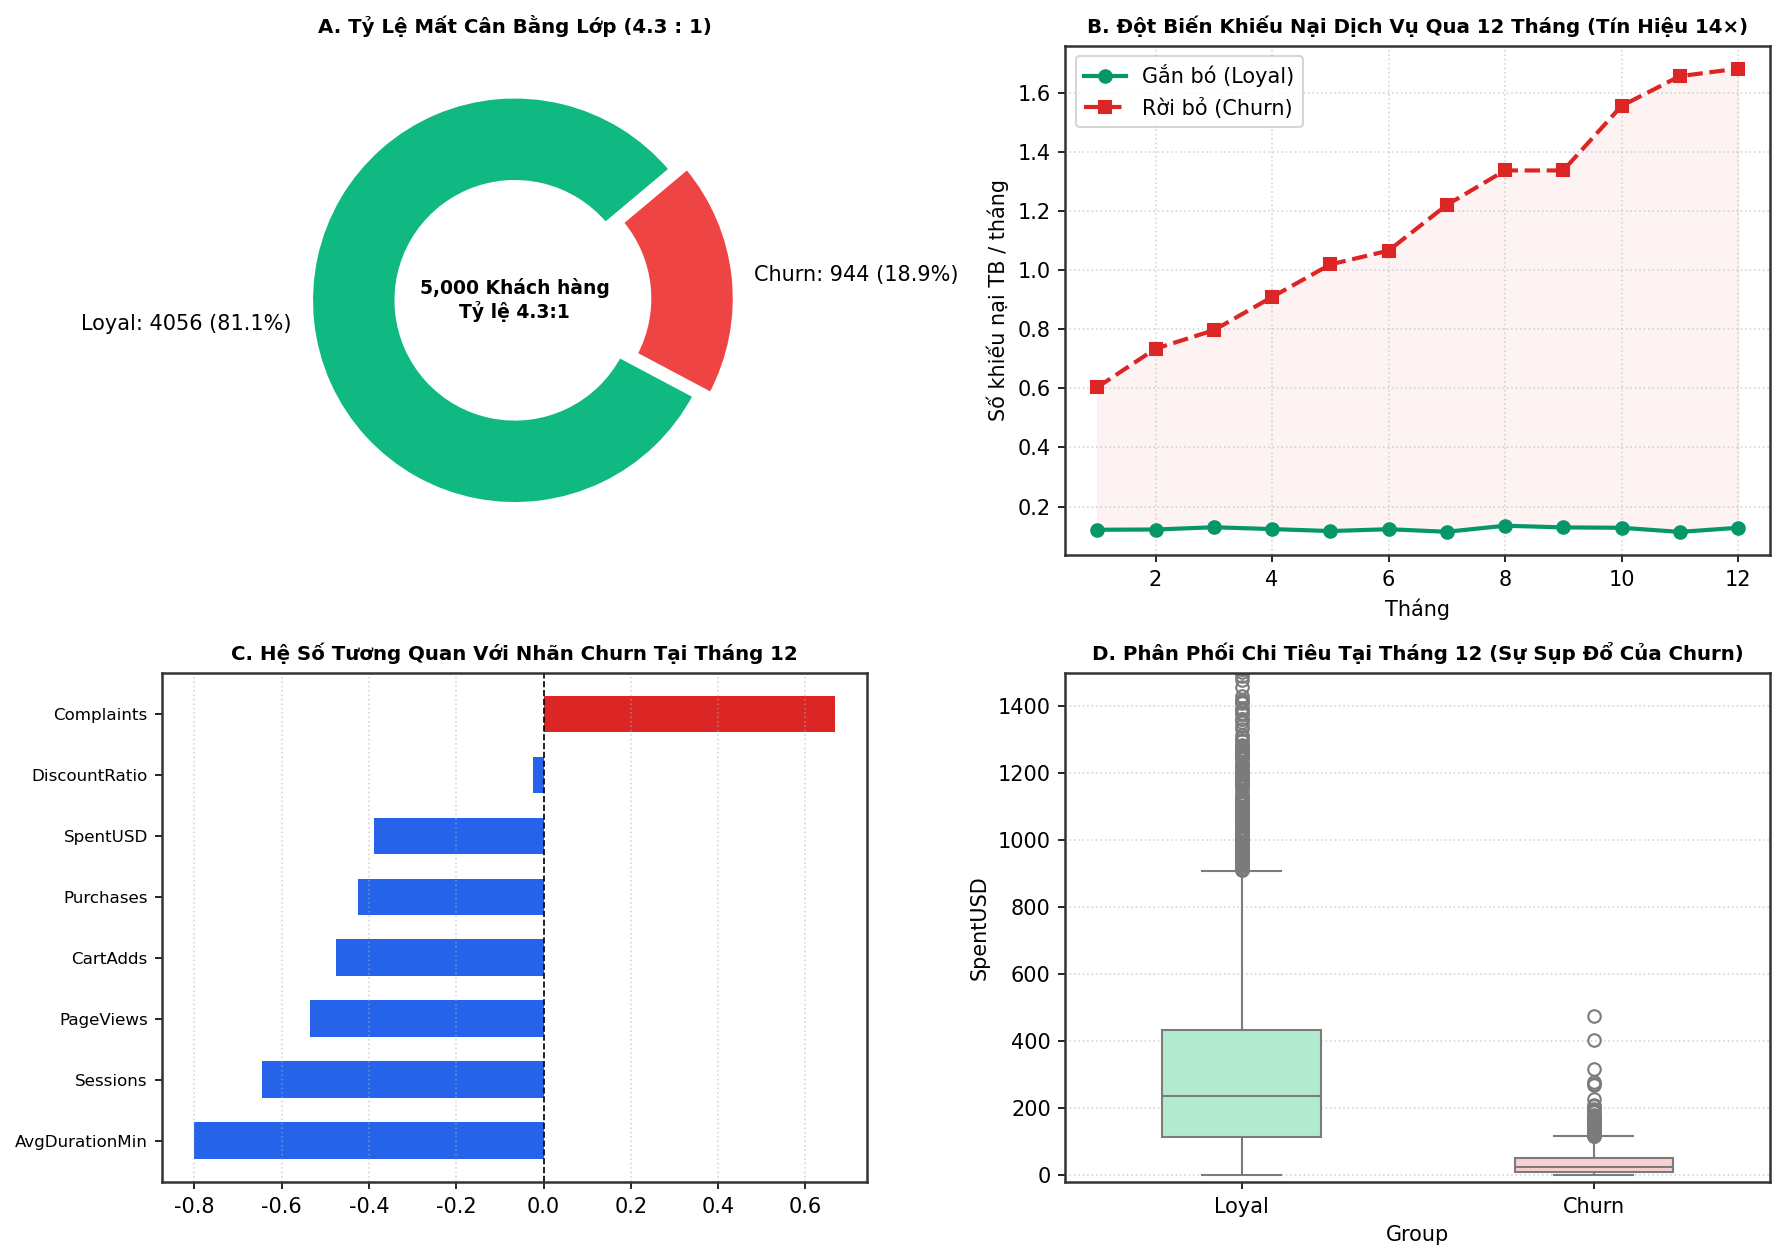

In [8]:
cust_summary = df_cust.groupby('CustomerID').agg({
    'Sessions': 'mean',
    'SpentUSD': 'mean',
    'Complaints': 'sum',
    'Purchases': 'mean',
    'AvgDurationMin': 'mean',
    'CartAdds': 'mean',
    'ChurnNextPeriod': 'first'
}).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), dpi=150)
plt.subplots_adjust(wspace=0.28, hspace=0.32)

# A. Class Imbalance Donut
n_loyal, n_churn = churn_counts[0], churn_counts[1]
pct_loyal, pct_churn = n_loyal / len(cust_summary) * 100, n_churn / len(cust_summary) * 100
axes[0, 0].pie([n_loyal, n_churn], labels=[f'Loyal: {n_loyal} ({pct_loyal:.1f}%)', f'Churn: {n_churn} ({pct_churn:.1f}%)'],
               colors=['#10b981', '#ef4444'], startangle=40, explode=(0, 0.08),
               wedgeprops=dict(width=0.42, edgecolor='white', lw=2))
axes[0, 0].text(0, 0, f"5,000 Khách hàng\nTỷ lệ {n_loyal/n_churn:.1f}:1", ha='center', va='center', fontsize=9, fontweight='bold')
axes[0, 0].set_title("A. Tỷ Lệ Mất Cân Bằng Lớp (4.3 : 1)", fontsize=9.5, fontweight='bold')

# B. Complaints Trajectory
loyal_c = df_cust[df_cust['ChurnNextPeriod'] == 0].groupby('Month')['Complaints'].mean()
churn_c = df_cust[df_cust['ChurnNextPeriod'] == 1].groupby('Month')['Complaints'].mean()
months = np.arange(1, 13)
axes[0, 1].plot(months, loyal_c, marker='o', color='#059669', lw=2, label='Gắn bó (Loyal)')
axes[0, 1].plot(months, churn_c, marker='s', color='#dc2626', lw=2, linestyle='--', label='Rời bỏ (Churn)')
axes[0, 1].fill_between(months, loyal_c, churn_c, color='#fee2e2', alpha=0.4)
axes[0, 1].set_title("B. Đột Biến Khiếu Nại Dịch Vụ Qua 12 Tháng (Tín Hiệu 14×)", fontsize=9.5, fontweight='bold')
axes[0, 1].set_xlabel("Tháng")
axes[0, 1].set_ylabel("Số khiếu nại TB / tháng")
axes[0, 1].grid(True, linestyle=':', alpha=0.5)
axes[0, 1].legend()

# C. Pearson Correlation with Churn in Month 12
features_all = ['AvgDurationMin', 'Sessions', 'PageViews', 'CartAdds', 'Purchases', 'SpentUSD', 'DiscountRatio', 'Complaints']
corr_m12 = df_cust[df_cust['Month'] == 12][features_all + ['ChurnNextPeriod']].corr()['ChurnNextPeriod'].drop('ChurnNextPeriod')
corr_m12_sorted = corr_m12.loc[features_all]
bar_cols = ['#dc2626' if c > 0 else '#2563eb' for c in corr_m12_sorted]
bars = axes[1, 0].barh(np.arange(len(features_all)), corr_m12_sorted.values, color=bar_cols, height=0.6)
axes[1, 0].axvline(0, color='black', lw=0.8, linestyle='--')
axes[1, 0].set_yticks(np.arange(len(features_all)))
axes[1, 0].set_yticklabels(features_all, fontsize=8)
axes[1, 0].set_title("C. Hệ Số Tương Quan Với Nhãn Churn Tại Tháng 12", fontsize=9.5, fontweight='bold')
axes[1, 0].grid(True, linestyle=':', alpha=0.5, axis='x')

# D. SpentUSD Boxplot
df_m12 = df_cust[df_cust['Month'] == 12].copy()
df_m12['Group'] = df_m12['ChurnNextPeriod'].map({0: 'Loyal', 1: 'Churn'})
sns.boxplot(x='Group', y='SpentUSD', hue='Group', data=df_m12, ax=axes[1, 1], palette=['#a7f3d0', '#fecaca'],
            width=0.45, legend=False)
axes[1, 1].set_title("D. Phân Phối Chi Tiêu Tại Tháng 12 (Sự Sụp Đổ Của Churn)", fontsize=9.5, fontweight='bold')
axes[1, 1].set_ylim(-20, 1500)
axes[1, 1].grid(True, linestyle=':', alpha=0.5, axis='y')

plt.tight_layout()
plt.show()


### 4.2. So Sánh Quỹ Đạo Toàn Diện: Số Phiên, Chi Tiêu, Lượt Mua & Thời Lượng Phiên

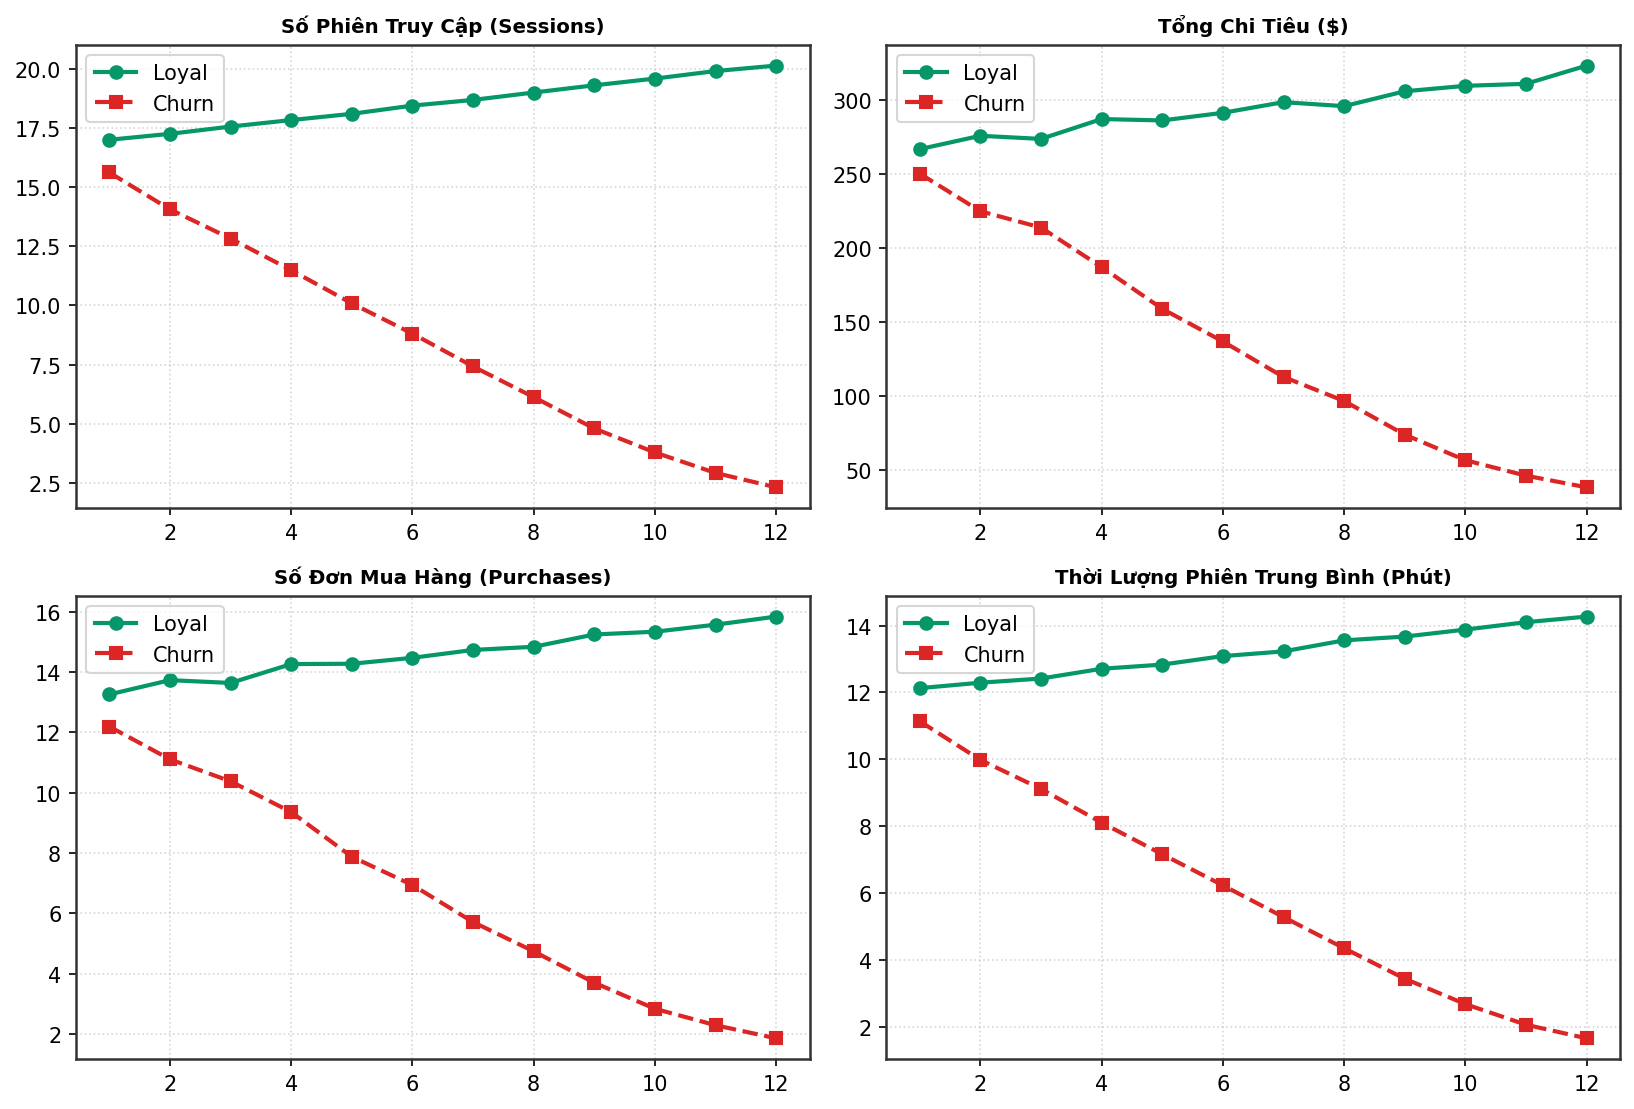

In [9]:
loyal_sessions = df_cust[df_cust['ChurnNextPeriod'] == 0].groupby('Month')['Sessions'].mean()
churn_sessions = df_cust[df_cust['ChurnNextPeriod'] == 1].groupby('Month')['Sessions'].mean()

loyal_spent = df_cust[df_cust['ChurnNextPeriod'] == 0].groupby('Month')['SpentUSD'].mean()
churn_spent = df_cust[df_cust['ChurnNextPeriod'] == 1].groupby('Month')['SpentUSD'].mean()

loyal_purch = df_cust[df_cust['ChurnNextPeriod'] == 0].groupby('Month')['Purchases'].mean()
churn_purch = df_cust[df_cust['ChurnNextPeriod'] == 1].groupby('Month')['Purchases'].mean()

loyal_dur = df_cust[df_cust['ChurnNextPeriod'] == 0].groupby('Month')['AvgDurationMin'].mean()
churn_dur = df_cust[df_cust['ChurnNextPeriod'] == 1].groupby('Month')['AvgDurationMin'].mean()

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), dpi=150)
months = np.arange(1, 13)

# Sessions
axes[0, 0].plot(months, loyal_sessions, marker='o', color='#059669', lw=2, label="Loyal")
axes[0, 0].plot(months, churn_sessions, marker='s', color='#dc2626', lw=2, linestyle='--', label="Churn")
axes[0, 0].set_title("Số Phiên Truy Cập (Sessions)", fontsize=9.5, fontweight='bold')
axes[0, 0].grid(True, linestyle=':', alpha=0.5)
axes[0, 0].legend()

# SpentUSD
axes[0, 1].plot(months, loyal_spent, marker='o', color='#059669', lw=2, label="Loyal")
axes[0, 1].plot(months, churn_spent, marker='s', color='#dc2626', lw=2, linestyle='--', label="Churn")
axes[0, 1].set_title("Tổng Chi Tiêu ($)", fontsize=9.5, fontweight='bold')
axes[0, 1].grid(True, linestyle=':', alpha=0.5)
axes[0, 1].legend()

# Purchases
axes[1, 0].plot(months, loyal_purch, marker='o', color='#059669', lw=2, label="Loyal")
axes[1, 0].plot(months, churn_purch, marker='s', color='#dc2626', lw=2, linestyle='--', label="Churn")
axes[1, 0].set_title("Số Đơn Mua Hàng (Purchases)", fontsize=9.5, fontweight='bold')
axes[1, 0].grid(True, linestyle=':', alpha=0.5)
axes[1, 0].legend()

# Duration
axes[1, 1].plot(months, loyal_dur, marker='o', color='#059669', lw=2, label="Loyal")
axes[1, 1].plot(months, churn_dur, marker='s', color='#dc2626', lw=2, linestyle='--', label="Churn")
axes[1, 1].set_title("Thời Lượng Phiên Trung Bình (Phút)", fontsize=9.5, fontweight='bold')
axes[1, 1].grid(True, linestyle=':', alpha=0.5)
axes[1, 1].legend()

plt.tight_layout()
plt.show()


## 5. Tiền Xử Lý Chuỗi Khách Hàng Thành Tensor 3D & Lưu Trữ Dữ Liệu Chuẩn Hóa
Đóng gói chuỗi 12 tháng với 8 đặc trưng thành Tensor `(5000, 12, 8)` và lưu ra file `.npz` để các notebook tiếp theo sử dụng.


In [10]:
cust_feat_cols = ['Sessions', 'PageViews', 'CartAdds', 'Purchases', 'AvgDurationMin', 'Complaints', 'SpentUSD', 'DiscountRatio']
scaler_cust = StandardScaler()
df_cust[cust_feat_cols] = scaler_cust.fit_transform(df_cust[cust_feat_cols])

X_cust_list = []
y_cust_list = []

for c_id in df_cust['CustomerID'].unique():
    sub = df_cust[df_cust['CustomerID'] == c_id].sort_values('Month')
    X_cust_list.append(sub[cust_feat_cols].values)
    y_cust_list.append(sub['ChurnNextPeriod'].iloc[0])

X_cust = np.array(X_cust_list, dtype=np.float32)
y_cust = np.array(y_cust_list, dtype=np.int64)

np.random.seed(42)
perm = np.random.permutation(len(X_cust))
split_c = int(len(X_cust) * 0.8)
X_cst_train, X_cst_test = X_cust[perm[:split_c]], X_cust[perm[split_c:]]
y_cst_train, y_cst_test = y_cust[perm[:split_c]], y_cust[perm[split_c:]]

print(f"X_cust Train Shape: {X_cst_train.shape} (N={X_cst_train.shape[0]}, T={X_cst_train.shape[1]}, D={X_cst_train.shape[2]})")
print(f"X_cust Test Shape : {X_cst_test.shape}")
print(f"y_cust Train Shape: {y_cst_train.shape}, Test Shape: {y_cst_test.shape}")

# Lưu dữ liệu đã tiền xử lý thành các file npz
out_stock_npz = os.path.join(PROCESSED_DIR, 'stock_amazon_processed.npz')
out_cust_npz = os.path.join(PROCESSED_DIR, 'customer_churn_processed.npz')

np.savez_compressed(out_stock_npz,
                    X_train=X_stk_train, y_train=y_stk_train,
                    X_test=X_stk_test, y_test=y_stk_test,
                    close_min=stock_scaler.data_min_[0],
                    close_max=stock_scaler.data_max_[0])

np.savez_compressed(out_cust_npz,
                    X_train=X_cst_train, y_train=y_cst_train,
                    X_test=X_cst_test, y_test=y_cst_test)

print(f"✓ Đã lưu file dữ liệu chứng khoán: {out_stock_npz}")
print(f"✓ Đã lưu file dữ liệu hành vi khách hàng: {out_cust_npz}")


X_cust Train Shape: (4000, 12, 8) (N=4000, T=12, D=8)
X_cust Test Shape : (1000, 12, 8)
y_cust Train Shape: (4000,), Test Shape: (1000,)
✓ Đã lưu file dữ liệu chứng khoán: /Users/phamvantu/Desktop/INTEL_SYS/src/Assigment 06/data/processed/stock_amazon_processed.npz
✓ Đã lưu file dữ liệu hành vi khách hàng: /Users/phamvantu/Desktop/INTEL_SYS/src/Assigment 06/data/processed/customer_churn_processed.npz
